In [1]:
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

from lib import neurons, input_gen, driver, utils

In [2]:
hyper = neurons.HyperConfig1(nd=200, ns=300, n=10, b=2., bk=5.5, beta=13.5153)
hyperD = neurons.HyperDynConfig1(b=2., bk=5.5, beta=13.5153)
neuron = neurons.Neuron_Decay_Int(hyper)
# xs_gen = input_gen.Normal(nd=hyper.nd, ns=hyper.ns)
xs_gen = input_gen.Normal_Corr_across_Dendrites(nd=hyper.nd, ns=hyper.ns, coeff=4, key=jax.random.PRNGKey(42))

my_driver = driver.Driver1_bScan_activationScan(
    neuron=neuron,
    xs_generator=xs_gen,
    rng=jax.random.PRNGKey(333),
    hyperD=hyperD,
    initial_state=None,
    resample_every=1000,
    n_tested_patterns=1000,
)

In [3]:
my_driver.run(
    n_init_steps=8000,
    n_steps_phase1=3000,
    n_steps_phase2=20000,
    n_steps_phase3=10000,
    test_every_phase3=50,
    bs=jnp.array([2.0]),
    window_lens=jnp.array([2.0]),
)

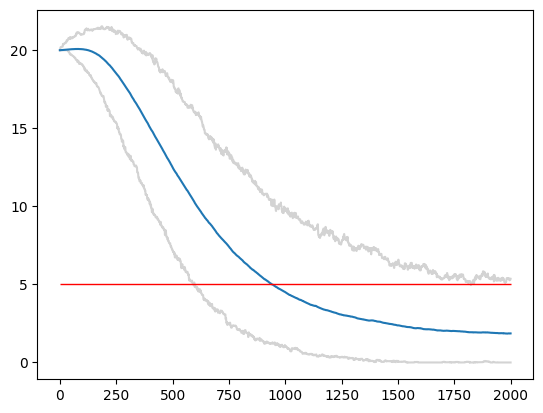

In [4]:
mean = np.mean(my_driver.transient_record, axis=-1)
lower = np.percentile(my_driver.transient_record, 1, axis=-1)
upper = np.percentile(my_driver.transient_record, 99, axis=-1)

steady_upper = np.percentile(my_driver.steady_record, 99, axis=-1)
steady_upper = np.mean(steady_upper, axis=0)

plt.plot(upper, color='lightgrey')
plt.plot(lower, color='lightgrey')
plt.plot(mean)
plt.hlines(steady_upper, 0, 2000, colors='red', linestyles='-', linewidth=1)

In [11]:
utils.capacity_numba(my_driver.transient_record, my_driver.steady_record)

array([586.])

In [10]:
my_driver.hyperD = neurons.HyperDynConfig1(b=2., bk=6.5, beta=13.5153)

In [ ]:
class Normal_Corr_across_Dendrites(input_gen.Normal):
    def __init__(self, nd, ns, coeff, key):
        """coeff: the ratio between number of axons and number of synapses per dendrite."""
        super().__init__(nd, ns)
        self.coeff = coeff
        self.nA = int(ns*coeff) # number of axons
        self.key, subkey = jax.random.split(key)
        self.conn_idx_mat = self._get_connectivity_idx_mat(subkey)

    def _get_connectivity_idx_mat(self, key) -> jnp.ndarray:
        key_list = jax.random.split(key, self.nd)
        fun = lambda key: jax.random.choice(key, jnp.arange(self.nA), (self.ns, ), replace=False) # each axon is chosen only once per dendrite
        conn_mat = jax.vmap(fun, in_axes=0)(key_list) # dim = (nd, ns)
        return conn_mat

    @partial(jax.jit, static_argnames=('self', 'n_patterns'))
    def _generate(self, rng, n_patterns: int):
        axon_inputs = jax.random.normal(rng, (n_patterns, self.nA))
        return axon_inputs[:, self.conn_idx_mat]
